# 06 - All four C-MAPSS datasets (FD001-FD004)

Runs the full pipeline (windows -> RUL -> failure risk -> SHAP) on every dataset with **one fixed set of rules**,
so results are comparable.

| Dataset | Conditions | Fault modes | What changes in preprocessing |
|---|---|---|---|
| FD001 | 1 | HPC | nothing (identical to 01_eda, checked array-by-array) |
| FD002 | 6 | HPC | per-regime normalisation |
| FD003 | 1 | HPC + fan | none, but s10 is no longer constant so it is kept |
| FD004 | 6 | HPC + fan | per-regime normalisation |

### Preprocessing decisions (evidence from the data, not assumed)
- **Regimes:** k-means on the 3 operating settings. For FD002/FD004 the within-cluster error drops to **exactly 0 at k=6**,
  matching the 6 conditions in the dataset readme. FD001/FD003 show no clusters, so they use 1 regime.
- **Per-regime MinMax scaling** (fitted on training engines only): in FD002/FD004 the regime alone explains about **100%** of raw
  sensor variance, so without it the model would learn the flight condition instead of wear.
- **Dropped sensors:** same rule as 01_eda (zero spread), applied **within every regime**, per dataset. No hard-coded list.
- **Short test engines:** FD002 has 6 and FD004 has 11 test engines with fewer than 30 cycles. They are padded by repeating their
  first cycle (no engine dropped), and their error is reported separately below.
- **Kept fixed for comparability:** window 30, RUL cap 125, 80/20 split by engine, model hyperparameters, H = 30, P cut-off 0.5.

### Models
- **XGBoost** (5 seeds): the model behind the SHAP, risk and dashboard work.
- **1D-CNN** (3 seeds): the deep-model representative (best deep test RMSE on FD001 and about 4-5x faster than LSTM/GRU).
  Architecture and training loop copied unchanged from 03 (`src/deep.py`).

In [1]:
import sys, time
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
import subprocess
import aerohealth as ah   # XGBoost only; the CNN runs in a separate process (see Section 1b)

SEEDS_XGB, SEEDS_CNN = [42, 1, 2, 3, 4], [42, 1, 2]
H, P_CUT = 30, 0.5

data = {}
for fd in ah.DATASETS:
    if not ah.windows_path(fd).exists():
        ah.prepare(fd)
    data[fd] = dict(ah.load_windows(fd))
    d = data[fd]
    print(f"{fd}: {len(d['features'])} sensors | train {d['X_tr'].shape[0]} windows | val {d['X_val'].shape[0]} | "
          f"test {len(d['y_test'])} engines | padded test engines {len(d.get('padded_engines', []))}")

/Users/chintansood7/miniforge3/envs/aerohealth/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FD001: 15 sensors | train 14241 windows | val 3490 | test 100 engines | padded test engines 0
FD002: 17 sensors | train 37432 windows | val 8787 | test 259 engines | padded test engines 6
FD003: 16 sensors | train 17692 windows | val 4128 | test 100 engines | padded test engines 0
FD004: 17 sensors | train 43523 windows | val 10505 | test 248 engines | padded test engines 11


## 1. RUL models on all datasets (multiple seeds)

In [2]:
runs, preds = [], {}
for fd, d in data.items():
    F_tr, F_val, F_te = (ah.summarize(d[k]) for k in ["X_tr", "X_val", "X_test"])
    pad = np.isin(d.get("test_engines", np.arange(1, len(d["y_test"]) + 1)), d.get("padded_engines", []))
    def record(model, seed, val_rmse, p, secs):
        runs.append({"dataset": fd, "model": model, "seed": seed, "val_RMSE": val_rmse,
                     "test_RMSE": ah.rmse(d["y_test"], p), "test_NASA": ah.nasa_score(d["y_test"], p),
                     "NASA_per_engine": ah.nasa_score(d["y_test"], p) / len(p),
                     "RMSE_padded_engines": ah.rmse(d["y_test"][pad], p[pad]) if pad.any() else np.nan,
                     "time_s": secs})
    for s in SEEDS_XGB:
        t0 = time.time(); m = ah.train_xgb(F_tr, d["y_tr"], seed=s); p = m.predict(F_te)
        record("XGBoost", s, ah.rmse(d["y_val"], m.predict(F_val)), p, time.time() - t0)
        if s == 42:
            preds[fd] = {"model": m, "p_val": m.predict(F_val), "p_test": p, "F_test": F_te}
    pd.DataFrame(runs).to_csv("../results/all_datasets_runs.csv", index=False)
    print(fd, "done")

xgb_runs = pd.DataFrame(runs)

FD001 done


FD002 done


FD003 done


FD004 done


### 1b. 1D-CNN in a separate process
XGBoost, scikit-learn and PyTorch each bundle their own OpenMP runtime on macOS. Training XGBoost and then PyTorch in one
process **segfaults** (reproduced and isolated). So the CNN runs via `src/run_cnn_all.py`, a separate process that never imports
XGBoost. This mirrors how 02 (trees) and 03 (deep) are already separate notebooks.

In [3]:
r = subprocess.run([sys.executable, "../src/run_cnn_all.py", *map(str, SEEDS_CNN)], capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:] if r.returncode else "")
assert r.returncode == 0, "CNN script failed"
runs_df = pd.concat([xgb_runs, pd.read_csv("../results/all_datasets_cnn_runs.csv")], ignore_index=True)
runs_df.to_csv("../results/all_datasets_runs.csv", index=False)

FD001 seed 42: test RMSE 14.71 (47s)
FD001 seed 1: test RMSE 14.45 (66s)
FD001 seed 2: test RMSE 15.12 (40s)
FD002 seed 42: test RMSE 27.36 (104s)
FD002 seed 1: test RMSE 28.23 (103s)
FD002 seed 2: test RMSE 27.31 (103s)
FD003 seed 42: test RMSE 14.73 (82s)
FD003 seed 1: test RMSE 15.21 (82s)
FD003 seed 2: test RMSE 14.54 (116s)
FD004 seed 42: test RMSE 28.39 (239s)
FD004 seed 1: test RMSE 28.26 (164s)
FD004 seed 2: test RMSE 26.98 (181s)
 


### Summary: mean ± std over seeds
`test_NASA` is a **sum** over test engines, so it grows with the number of engines (FD002/FD004 have about 2.5x more).
Use **NASA_per_engine** to compare datasets.

In [4]:
agg = runs_df.groupby(["dataset", "model"])[["val_RMSE", "test_RMSE", "test_NASA", "NASA_per_engine", "time_s"]].agg(["mean", "std"])
agg.round(2).to_csv("../results/all_datasets_summary.csv")
table = pd.DataFrame({c: agg[(c, "mean")].round(2).astype(str) + " ± " + agg[(c, "std")].round(2).astype(str)
                      for c in ["test_RMSE", "NASA_per_engine", "val_RMSE"]})
table["time_s"] = agg[("time_s", "mean")].round(0)
table

test_RMSE NASA_per_engine      val_RMSE  time_s
dataset model                                                      
FD001   1D-CNN   14.76 ± 0.34     3.62 ± 0.14  11.98 ± 0.05    51.0
        XGBoost  13.89 ± 0.22      2.86 ± 0.1  12.42 ± 0.06     1.0
FD002   1D-CNN   27.63 ± 0.52    45.69 ± 7.06  16.01 ± 0.31   103.0
        XGBoost  26.71 ± 0.17     29.87 ± 1.6  16.04 ± 0.11     2.0
FD003   1D-CNN   14.83 ± 0.35     4.72 ± 0.41  11.76 ± 0.06    93.0
        XGBoost   14.2 ± 0.19      4.3 ± 0.26  11.02 ± 0.07     2.0
FD004   1D-CNN   27.88 ± 0.78    23.23 ± 1.88  17.66 ± 0.24   194.0
        XGBoost  28.25 ± 0.15    25.87 ± 1.03  17.88 ± 0.08     2.0

### Short (padded) test engines
Padding repeats the first recorded cycle, so the window carries less information. Compare their RMSE with the dataset's overall test RMSE.

In [5]:
runs_df.dropna(subset=["RMSE_padded_engines"]).groupby(["dataset", "model"])[["test_RMSE", "RMSE_padded_engines"]].mean().round(2)

test_RMSE  RMSE_padded_engines
dataset model                                  
FD002   1D-CNN       27.63                35.32
        XGBoost      26.71                39.76
FD004   1D-CNN       27.88                43.50
        XGBoost      28.25                48.78

## 2. Failure risk on all datasets (XGBoost seed 42, same rules as 05)
Calibration fitted on each dataset's **validation** engines. HIGH = P(fail within H) >= cut-off, MEDIUM = P(fail within 2H) >= cut-off.

In [6]:
rows = []
for fd, d in data.items():
    pv, pt = preds[fd]["p_val"], preds[fd]["p_test"]
    cal_H, cal_2H = ah.fit_calibration(pv, d["y_val"], H), ah.fit_calibration(pv, d["y_val"], 2 * H)
    level = ah.risk_levels(ah.prob(cal_H, pt), ah.prob(cal_2H, pt), P_CUT)
    preds[fd]["level"] = level
    true, hi = d["y_test"] <= H, level == "HIGH"
    rows.append({"dataset": fd, "test engines": len(pt), f"truly fail <= {H}": int(true.sum()),
                 "HIGH": int(hi.sum()), "MEDIUM": int((level == "MEDIUM").sum()), "LOW": int((level == "LOW").sum()),
                 "HIGH recall": f"{(hi & true).sum()}/{true.sum()}", "HIGH precision": f"{(hi & true).sum()}/{hi.sum()}",
                 "fail <= H but LOW": int((true & (level == "LOW")).sum()),
                 "derived HIGH cut-off": round(ah.derived_cutoff(cal_H, P_CUT), 1)})
risk_df = pd.DataFrame(rows)
risk_df.to_csv("../results/all_datasets_risk.csv", index=False)
risk_df

,dataset,test engines,truly fail <= 30,HIGH,MEDIUM,LOW,HIGH recall,HIGH precision,fail <= H but LOW,derived HIGH cut-off
0,FD001,100,25,24,10,66,23/25,23/24,0,31.6
1,FD002,259,61,68,45,146,61/61,61/68,0,35.1
2,FD003,100,20,21,19,60,19/20,19/21,0,32.0
3,FD004,248,53,46,40,162,43/53,43/46,0,31.5


## 3. SHAP: which sensors drive the model on each dataset? (XGBoost seed 42)
FD001/FD002 have only **HPC** degradation, FD003/FD004 add **fan** degradation. If the explanations are physically meaningful,
fan-related sensors should matter more on FD003/FD004.

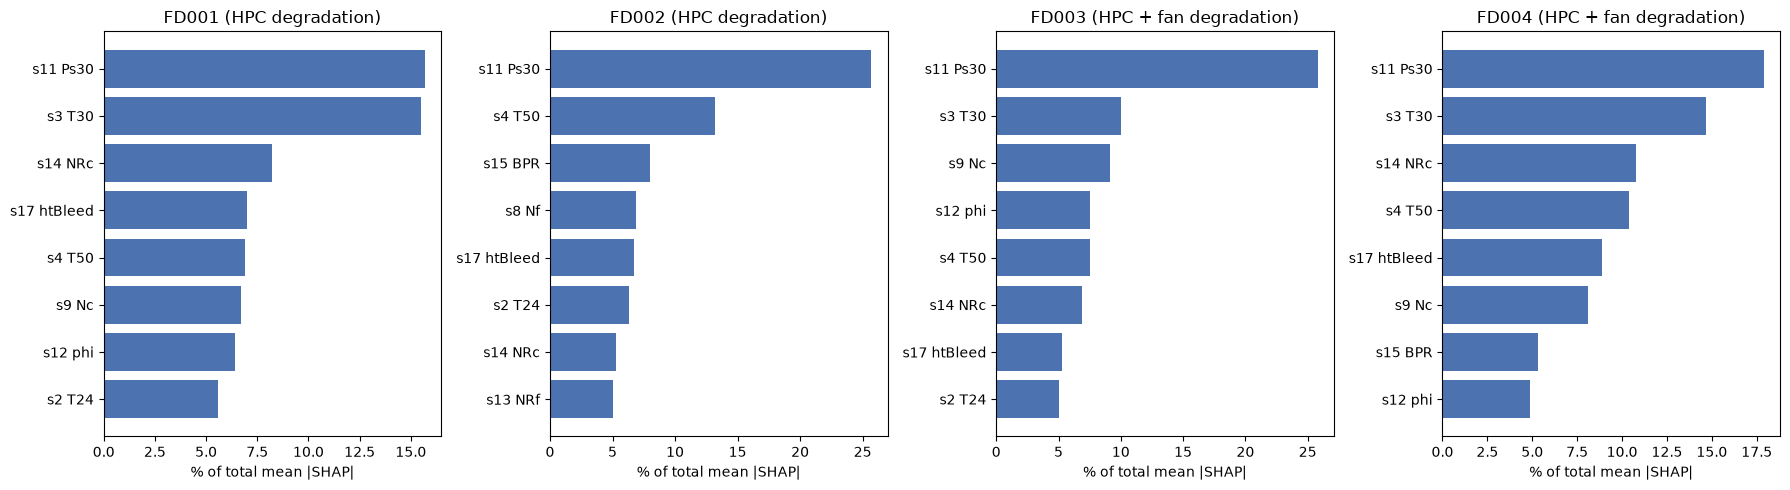

,FD001,FD002,FD003,FD004
#1,s11 (Ps30) 15.7%,s11 (Ps30) 25.7%,s11 (Ps30) 25.8%,s11 (Ps30) 17.9%
#2,s3 (T30) 15.5%,s4 (T50) 13.2%,s3 (T30) 10.0%,s3 (T30) 14.7%
#3,s14 (NRc) 8.2%,s15 (BPR) 8.0%,s9 (Nc) 9.1%,s14 (NRc) 10.8%
#4,s17 (htBleed) 7.0%,s8 (Nf) 6.9%,s12 (phi) 7.5%,s4 (T50) 10.4%
#5,s4 (T50) 6.9%,s17 (htBleed) 6.7%,s4 (T50) 7.5%,s17 (htBleed) 8.9%


In [7]:
imp_rows = {}
for fd, d in data.items():
    sv = shap.TreeExplainer(preds[fd]["model"]).shap_values(preds[fd]["F_test"])
    sensors = list(d["features"])
    imp = np.abs(sv).mean(0).reshape(len(ah.STATS), len(sensors)).sum(0)
    imp_rows[fd] = pd.Series(imp, index=sensors)
imp_df = pd.DataFrame(imp_rows).fillna(0)
share = (imp_df / imp_df.sum() * 100).round(1)
share.to_csv("../results/shap_sensor_share_all.csv")

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=False)
for ax, fd in zip(axes, ah.DATASETS):
    top = share[fd].sort_values().tail(8)
    ax.barh([f"{s} {ah.SENSOR_NAMES[s].split()[0]}" for s in top.index], top.values, color="#4C72B0")
    ax.set_title(f"{fd} ({ah.FAULT_MODES[fd]})"); ax.set_xlabel("% of total mean |SHAP|")
plt.tight_layout(); plt.savefig("../results/shap_sensor_importance_all.png", dpi=150); plt.show()

top5 = pd.DataFrame({fd: [f"{s} ({ah.SENSOR_NAMES[s].split()[0]}) {share.loc[s, fd]:.1f}%" for s in share[fd].sort_values(ascending=False).index[:5]]
                     for fd in ah.DATASETS}, index=[f"#{i}" for i in range(1, 6)])
top5

In [8]:
fan = ["s8", "s13", "s15"]   # Nf, NRf, BPR: fan speed and bypass ratio
print("Share of SHAP importance on fan-related sensors (%):")
share.reindex(fan).fillna(0).sum().round(1)

Share of SHAP importance on fan-related sensors (%):


FD001    13.4
FD002    19.9
FD003    12.0
FD004     9.6
dtype: float32

## 4. Findings (seeded runs; numbers in the tables above)
1. **Failure risk generalises:** on all four datasets **no engine that fails within 30 cycles is rated LOW**, with the same
   rules and no re-tuning. FD004 has the lowest HIGH recall (the rest of its truly-failing engines are rated MEDIUM).
2. **Multi-condition datasets are much harder:** test RMSE is about 27-28 on FD002/FD004 against about 14 on FD001/FD003. Published
   methods do better on FD002/FD004. This notebook is a **same-recipe, untuned** comparison and makes no state-of-the-art claim.
3. **XGBoost vs 1D-CNN:** XGBoost has lower test RMSE on FD001-FD003. On FD004 the CNN is slightly lower but within its seed std,
   so call it a tie. Seeds capture training randomness only, not test-set sampling noise.
4. **Padding costs accuracy:** padded short engines have clearly higher error than the dataset average (Section 1).
5. **Fan-fault check is negative:** fan-related sensors do **not** gain importance on FD003/FD004 (fan + HPC faults) compared with
   FD001/FD002 (HPC only). The model relies mainly on HPC sensors (s11 Ps30, s3 T30) everywhere, so **we cannot claim it
   detects fan degradation specifically.**

## 5. Notes and limitations
- **NASA score is a sum**: compare datasets with `NASA_per_engine`, not `test_NASA`.
- **FD004 sensor s6** (bypass-duct pressure) reads below every training value in 2 test engines (39 of 126,480 values).
  This is a single-sensor quirk, not a regime error (a wrong regime would shift every sensor). Trees treat it as the lowest seen value.
- **1D-CNN uses 3 seeds** (CPU time). The std column shows the remaining uncertainty.
- **Hyperparameters were tuned on none of the datasets.** FD001 settings are reused everywhere, so FD002-FD004 results are a
  fair "same recipe" comparison, not the best achievable.
- **SHAP explains the model**, not physical causation. Correlated sensors can share importance.